## 1. Выбор данных

Датасет flight_data_2024_sample.csv содержит 10 000 записей и 35 признаков о внутренних пассажирских авиарейсах США за 2024 год.

- Один объект в данных — один запланированный внутренний авиарейс между двумя аэропортами США в конкретную дату.
- Исходные переменные описывают календарные параметры (month, day_of_week, fl_date), перевозчика и номер рейса (op_unique_carrier, op_carrier_fl_num), аэропорты вылета и прилета (origin, dest), плановое и фактическое время вылета, руления и прилета (crs_dep_time, dep_delay, taxi_out, taxi_in, arr_delay), дальность маршрута (distance), статусы отмены и перенаправления (cancelled, diverted), а также разложение задержки по причинам (carrier_delay, weather_delay, nas_delay, security_delay, late_aircraft_delay).
- Для построения интерпретируемой байесовской сети выбраны 7 переменных, описывающих условия и этапы выполнения рейса:
  - Season — сезон вылета (Зима, Весна, Лето, Осень) по полю month.
  - TimeOfDay — время суток планового вылета (Утро, День, Вечер) по полю crs_dep_time.
  - BusyOrigin — признак вылета из крупного аэропорта-хаба (1 — топ-10 аэропортов выборки по числу рейсов, 0 — остальные).
  - Distance — категория дальности рейса (Короткий, Средний, Дальний) по полю distance.
  - DepDelay — задержка вылета от 15 минут (1 — есть, 0 — нет) по полю dep_delay.
  - LongTaxiOut — длительное руление перед взлетом от 20 минут (1 — есть, 0 — нет) по полю taxi_out.
  - ArrDelay — задержка прилета от 15 минут (1 — есть, 0 — нет) по полю arr_delay.
- Предполагаемые зависимости: сезон, время суток и загруженность аэропорта вылета влияют на вероятность задержки вылета; загруженность аэропорта вылета влияет на длительность руления перед взлетом; задержка вылета, длительное руление и дальность маршрута совместно определяют вероятность задержки прилета.

Признаки причин задержек (carrier_delay, weather_delay, nas_delay, late_aircraft_delay) не включаются в модель в качестве родителей ArrDelay: в данных Бюро транспортной статистики США они фиксируются ненулевыми только при условии arr_delay >= 15 минут, что создало бы искусственную зависимость из-за правил сбора статистики.

In [3]:
# %pip install pgmpy==1.1.2 numpy==2.3.5 pandas==2.2.3 matplotlib==3.10.8 networkx==3.7

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 30.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 90.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 64.1 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0
    Uninstalling matplotlib-3.10.0:
      Successfully uninstalled matplotlib-3.10.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pgmpy]


In [4]:
import warnings
from collections.abc import Mapping, Sequence
from itertools import product

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message=r"`pgmpy\.estimators\.StructureScore` is deprecated.*",
        category=FutureWarning,
    )
    from pgmpy.inference import VariableElimination
    from pgmpy.models import DiscreteBayesianNetwork
    from pgmpy.parameter_estimator import DiscreteBayesianEstimator, DiscreteMLE

DATA_PATH = "flight_data_2024_sample.csv"
SEED = 42
EQUIVALENT_SAMPLE_SIZE = 5

COLORS = {"main": "#2855A6", "accent": "#B9577A", "muted": "#7B818C"}

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 120,
    "font.family": "DejaVu Sans",
    "font.size": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
})
pd.set_option("display.max_columns", 12)
pd.set_option("display.precision", 4)

## 2. Подготовка данных

- Пропущенные значения: в исходной таблице 10 000 рейсов, из них 122 отменены (cancelled = 1) и 42 перенаправлены (diverted = 1). Все 164 пропуска в arr_delay и air_time, а также пропуски в dep_delay и taxi_out приходятся исключительно на отмененные и перенаправленные рейсы. Поле cancellation_code заполнено только для отмененных рейсов (98.78% пропусков). После фильтрации выполненных рейсов (cancelled = 0 и diverted = 0) остается 9 836 записей с нулевым числом пропусков по всем выбранным переменным.
- Редкие категории: признак origin содержит 284 уникальных аэропорта, среди которых много редких региональных направлений; прямое включение origin привело бы к комбинаторному взрыву таблиц CPT. Поэтому аэропорты свернуты в бинарный признак BusyOrigin (топ-10 крупнейших хабов: ATL, DFW, DEN, ORD, CLT, PHX, LAX, LAS, LGA, MCO — 33.25% выборки). Также исключен крайне редкий признак security_delay (менее 0.1% ненулевых значений).
- Способ дискретизации непрерывных признаков:
  - dep_delay и arr_delay переведены в бинарные индикаторы по официальному стандарту Федерального управления гражданской авиации США (FAA): задержка >= 15 минут.
  - taxi_out дискретизирован по порогу >= 20 минут (близко к 75-му перцентилю 21 минута, отделяет штатное руление от очередей на ВПП).
  - crs_dep_time разбит на три интервала суток: Утро (00:00–11:59), День (12:00–17:59), Вечер (18:00–23:59), отражающие накопление сбоев в расписании.
  - month сгруппирован в четыре календарных сезона: Зима, Весна, Лето, Осень.
  - distance разбит на три содержательных диапазона: Короткий (до 500 миль), Средний (500–1200 миль), Дальний (свыше 1200 миль).
- Число состояний и достаточность наблюдений: у каждой переменной от 2 до 4 состояний. Наибольшая таблица условных вероятностей у узла DepDelay имеет 4 * 3 * 2 = 24 комбинации родителей, у узла ArrDelay — 2 * 2 * 3 = 12 комбинаций. На 9 836 наблюдениях минимальное число примеров в одной комбинации родителей составляет 188 для DepDelay и 151 для ArrDelay, что достаточно для устойчивой оценки вероятностей.

In [5]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw[(df_raw["cancelled"] == 0) & (df_raw["diverted"] == 0)].copy()

summary_missing = pd.DataFrame({
    "Признак": ["dep_delay", "taxi_out", "arr_delay", "air_time", "cancellation_code"],
    "Пропуски (исходно)": [int(df_raw[c].isna().sum()) for c in ["dep_delay", "taxi_out", "arr_delay", "air_time", "cancellation_code"]],
    "Доля пропусков, %": [round(df_raw[c].isna().mean() * 100, 2) for c in ["dep_delay", "taxi_out", "arr_delay", "air_time", "cancellation_code"]],
    "Пропуски (выполненные)": [int(df[c].isna().sum()) for c in ["dep_delay", "taxi_out", "arr_delay", "air_time", "cancellation_code"]],
})
print(f"Всего рейсов: {len(df_raw)}, отменено: {(df_raw['cancelled'] == 1).sum()}, перенаправлено: {(df_raw['diverted'] == 1).sum()}")
print(f"Выполненных рейсов для моделирования: {len(df)}")
display(summary_missing)

top10_origins = df["origin"].value_counts().head(10).index.tolist()
season_map = {
    12: "Зима", 1: "Зима", 2: "Зима",
    3: "Весна", 4: "Весна", 5: "Весна",
    6: "Лето", 7: "Лето", 8: "Лето",
    9: "Осень", 10: "Осень", 11: "Осень",
}

data = pd.DataFrame({
    "Season": df["month"].map(season_map),
    "TimeOfDay": pd.cut(
        df["crs_dep_time"] // 100,
        bins=[-1, 11, 17, 25],
        labels=["Утро", "День", "Вечер"],
    ).astype(str),
    "BusyOrigin": df["origin"].isin(top10_origins).astype(int),
    "Distance": pd.cut(
        df["distance"],
        bins=[0, 500, 1200, 10000],
        labels=["Короткий", "Средний", "Дальний"],
    ).astype(str),
    "DepDelay": (df["dep_delay"] >= 15).astype(int),
    "LongTaxiOut": (df["taxi_out"] >= 20).astype(int),
    "ArrDelay": (df["arr_delay"] >= 15).astype(int),
}).reset_index(drop=True)

assert not data.isna().any().any()

STATE_NAMES = {
    "Season": ["Зима", "Весна", "Лето", "Осень"],
    "TimeOfDay": ["Утро", "День", "Вечер"],
    "BusyOrigin": [0, 1],
    "Distance": ["Короткий", "Средний", "Дальний"],
    "DepDelay": [0, 1],
    "LongTaxiOut": [0, 1],
    "ArrDelay": [0, 1],
}
NODES = tuple(STATE_NAMES.keys())

states_summary = pd.DataFrame([
    {
        "Переменная": col,
        "Число состояний": len(STATE_NAMES[col]),
        "Состояния": ", ".join(map(str, STATE_NAMES[col])),
        "Мин. частота состояния": int(data[col].value_counts().min()),
    }
    for col in NODES
])
display(states_summary)

dep_support = data.groupby(["Season", "TimeOfDay", "BusyOrigin"])["DepDelay"].agg(n="size", rate="mean")
arr_support = data.groupby(["DepDelay", "LongTaxiOut", "Distance"])["ArrDelay"].agg(n="size", rate="mean")
print(f"Поддержка комбинаций родителей DepDelay: min={dep_support['n'].min()}, max={dep_support['n'].max()}")
print(f"Поддержка комбинаций родителей ArrDelay: min={arr_support['n'].min()}, max={arr_support['n'].max()}")

Всего рейсов: 10000, отменено: 122, перенаправлено: 42
Выполненных рейсов для моделирования: 9836


,Признак,Пропуски (исходно),"Доля пропусков, %",Пропуски (выполненные)
0,dep_delay,116,1.16,0
1,taxi_out,120,1.20,0
2,arr_delay,164,1.64,0
3,air_time,164,1.64,0
4,cancellation_code,9878,98.78,9836


,Переменная,Число состояний,Состояния,Мин. частота состояния
0,Season,4,"Зима, Весна, Лето, Осень",2221
1,TimeOfDay,3,"Утро, День, Вечер",2170
2,BusyOrigin,2,"0, 1",3270
3,Distance,3,"Короткий, Средний, Дальний",1928
4,DepDelay,2,"0, 1",2042
5,LongTaxiOut,2,"0, 1",2849
6,ArrDelay,2,"0, 1",2119


Поддержка комбинаций родителей DepDelay: min=188, max=760
Поддержка комбинаций родителей ArrDelay: min=151, max=2651


## 3. Постановка вопросов

До построения сети сформулированы следующие вопросы к вероятностной модели:

1. Как изменится вероятность задержки прилета ArrDelay = 1, если известно, что рейс запланирован на летний вечер (Season = Лето, TimeOfDay = Вечер)?
2. Какова вероятность задержки прилета ArrDelay = 1 при уже возникшей задержке вылета DepDelay = 1 для коротких и дальних рейсов (Distance = Короткий и Distance = Дальний)?
3. Если известно, что рейс прибыл с опозданием (ArrDelay = 1), какова вероятность, что задержка возникла уже на вылете (DepDelay = 1), и как эта оценка изменится, если дополнительно узнать, что перед взлетом было длительное руление (LongTaxiOut = 1 или LongTaxiOut = 0)?
4. Как последовательное добавление наблюдений о задержке прилета, длительности руления, времени суток и сезоне изменяет распределение вероятности задержки вылета DepDelay = 1?

## 4. Построение графа

Предлагаемая структура представляет собой ориентированный ациклический граф (DAG) из 7 узлов и 7 ребер. Обоснование зависимостей и направлений связей:

- Season -> DepDelay: погодные условия и сезонная пиковая нагрузка на авиасеть (летние грозы, отпускной трафик) влияют на задержки вылета. Направление однозначно задано временем: сезон предшествует вылету.
- TimeOfDay -> DepDelay: в течение дня задержки предыдущих рейсов накапливаются по цепочке оборота воздушных судов, поэтому вечерние вылеты задерживаются чаще утренних. Плановое время вылета задается расписанием заранее.
- BusyOrigin -> DepDelay: в крупнейших хабах выше плотность трафика, нагрузка на гейты и наземное обслуживание, что увеличивает риск задержки вылета.
- BusyOrigin -> LongTaxiOut: в крупных аэропортах длиннее маршруты руления и чаще образуются очереди на взлетно-посадочной полосе. Тип аэропорта определяет условия руления, а не наоборот.
- DepDelay -> ArrDelay: задержка вылета от гейта напрямую сдвигает время прилета. Направление соответствует хронологии полета.
- LongTaxiOut -> ArrDelay: длительное руление перед взлетом увеличивает фактическую длительность рейса и повышает риск опоздания прилета даже при своевременном вылете от гейта.
- Distance -> ArrDelay: протяженность маршрута фиксирована до вылета; на дальних рейсах у экипажа больше запаса в расписании и возможностей компенсировать задержку в полете за счет скорости или спрямления трассы.

Факторизация совместного распределения имеет вид:

$$P(\text{Season}, \text{TimeOfDay}, \text{BusyOrigin}, \text{Distance}, \text{DepDelay}, \text{LongTaxiOut}, \text{ArrDelay}) = P(\text{Season}) P(\text{TimeOfDay}) P(\text{BusyOrigin}) P(\text{Distance}) P(\text{DepDelay} \mid \text{Season}, \text{TimeOfDay}, \text{BusyOrigin}) P(\text{LongTaxiOut} \mid \text{BusyOrigin}) P(\text{ArrDelay} \mid \text{DepDelay}, \text{LongTaxiOut}, \text{Distance}).$$

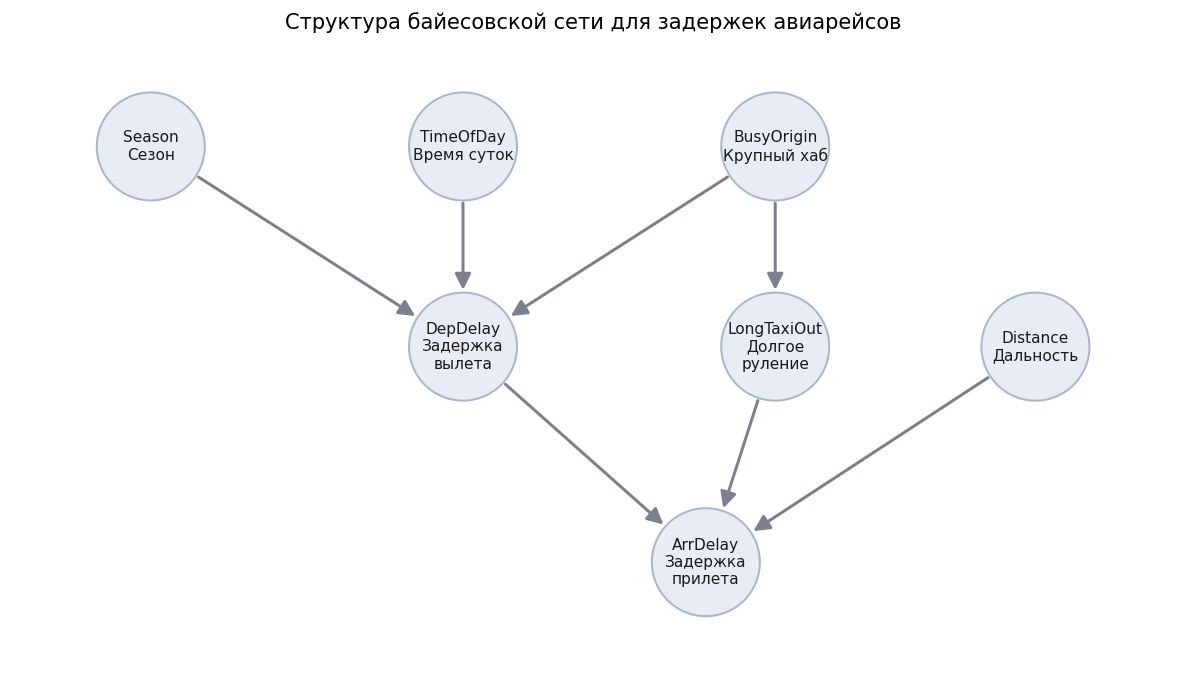

In [6]:
EDGES = (
    ("Season", "DepDelay"),
    ("TimeOfDay", "DepDelay"),
    ("BusyOrigin", "DepDelay"),
    ("BusyOrigin", "LongTaxiOut"),
    ("DepDelay", "ArrDelay"),
    ("LongTaxiOut", "ArrDelay"),
    ("Distance", "ArrDelay"),
)

POSITIONS = {
    "Season": (-2.4, 1.5),
    "TimeOfDay": (-0.6, 1.5),
    "BusyOrigin": (1.2, 1.5),
    "Distance": (2.7, 0.2),
    "DepDelay": (-0.6, 0.2),
    "LongTaxiOut": (1.2, 0.2),
    "ArrDelay": (0.8, -1.2),
}

LABELS = {
    "Season": "Season\nСезон",
    "TimeOfDay": "TimeOfDay\nВремя суток",
    "BusyOrigin": "BusyOrigin\nКрупный хаб",
    "Distance": "Distance\nДальность",
    "DepDelay": "DepDelay\nЗадержка\nвылета",
    "LongTaxiOut": "LongTaxiOut\nДолгое\nруление",
    "ArrDelay": "ArrDelay\nЗадержка\nприлета",
}

def draw_network(
    model: DiscreteBayesianNetwork,
    observed: Sequence[str] = (),
    title: str = "Структура байесовской сети",
) -> None:
    observed = set(observed)
    fig, ax = plt.subplots(figsize=(10, 5.8))
    node_colors = [COLORS["main"] if node in observed else "#E8EDF5" for node in model.nodes()]
    nx.draw_networkx_nodes(
        model, POSITIONS, ax=ax, node_size=4_200,
        node_color=node_colors, edgecolors="#A9B6CB", linewidths=1.2,
    )
    nx.draw_networkx_edges(
        model, POSITIONS, ax=ax, arrows=True, arrowsize=20,
        width=1.8, edge_color=COLORS["muted"],
        min_source_margin=34, min_target_margin=34,
    )
    for node, (x, y) in POSITIONS.items():
        if node in model:
            ax.text(
                x, y, LABELS[node], ha="center", va="center", fontsize=9.2,
                color="white" if node in observed else "#1A1A1A",
            )
    ax.set(title=title, xlim=(-3.2, 3.5), ylim=(-1.9, 2.2))
    ax.axis("off")
    fig.tight_layout()
    plt.show()

structure = DiscreteBayesianNetwork(EDGES)
structure.add_nodes_from(NODES)
assert nx.is_directed_acyclic_graph(structure)
draw_network(structure, title="Структура байесовской сети для задержек авиарейсов")

## 5. Условные вероятности

Параметры сети оценены с помощью байесовского оценивания BDeu (equivalent_sample_size = 5), что защищает редкие комбинации от нулевых вероятностей и при достаточном объеме выборки практически совпадает с MLE.

Анализ полученных таблиц условных вероятностей (CPT):

- Маргинальные вероятности, вычисленные по сети, совпадают с эмпирическими частотами в данных с точностью до 0.0004 (например, для ArrDelay = 1: 0.2158 по модели против 0.2154 в данных; для DepDelay = 1: 0.2073 против 0.2076).
- В таблице LongTaxiOut | BusyOrigin подтверждается ожидание: в крупных хабах долгое руление случается в 34.84% случаев против 26.05% в остальных аэропортах.
- В таблице DepDelay | Season, TimeOfDay, BusyOrigin наиболее высокая вероятность задержки вылета наблюдается летом вечером в крупном хабе (45.30%), а наименьшая — осенью утром вне крупных хабов (9.90%). Это согласуется с эффектом накопления задержек к вечеру и летней пиковой нагрузкой.
- В таблице ArrDelay | DepDelay, LongTaxiOut, Distance выделяются два важных эффекта:
  1. При своевременном вылете (DepDelay = 0) долгое руление резко повышает риск опоздания прилета: например, для коротких рейсов с 1.36% до 13.80% (почти в 10 раз).
  2. Необычный, но содержательно объяснимый результат по дальности: если задержка вылета уже произошла (DepDelay = 1), то на дальних рейсах вероятность опоздания прилета заметно ниже, чем на коротких — 71.55% против 78.39% при обычном рулении и 82.03% против 93.59% при долгом рулении. Причина в том, что расписание дальних рейсов закладывает больший резерв времени (schedule padding), а продолжительный крейсерский участок позволяет экипажу частично нагнать отставание в воздухе.

In [7]:
def fit_network(
    df_in: pd.DataFrame,
    edges: Sequence[tuple[str, str]],
    method: str = "bdeu",
    equivalent_sample_size: float = EQUIVALENT_SAMPLE_SIZE,
) -> DiscreteBayesianNetwork:
    model = DiscreteBayesianNetwork(edges)
    model.add_nodes_from(NODES)
    if method == "mle":
        estimator = DiscreteMLE(state_names=STATE_NAMES, n_jobs=1)
    elif method == "bdeu":
        estimator = DiscreteBayesianEstimator(
            state_names=STATE_NAMES,
            prior_type="BDeu",
            equivalent_sample_size=equivalent_sample_size,
            n_jobs=1,
        )
    else:
        raise ValueError(f"Неизвестный метод: {method}")
    model.fit(df_in, estimator=estimator)
    assert model.check_model()
    return model

def cpd_frame(model: DiscreteBayesianNetwork, node: str) -> pd.DataFrame:
    cpd = model.get_cpds(node)
    parents = cpd.variables[1:]
    parent_states = [cpd.state_names[p] for p in parents]
    rows = []
    for combo in product(*parent_states):
        cond = dict(zip(parents, combo))
        row = cond.copy()
        for state in cpd.state_names[node]:
            row[f"P({node}={state})"] = float(cpd.get_value(**{node: state, **cond}))
        rows.append(row)
    return pd.DataFrame(rows)

def probability(
    inference: VariableElimination,
    target: str,
    evidence: Mapping[str, object] | None = None,
    state: object = 1,
) -> float:
    result = inference.query(
        variables=[target],
        evidence={} if evidence is None else dict(evidence),
        show_progress=False,
    )
    return float(result.get_value(**{target: state}))

model = fit_network(data, EDGES, method="bdeu")
inference = VariableElimination(model)

marg_check = pd.DataFrame([
    {
        "Переменная": f"{n}=1",
        "Эмпирическая доля": float((data[n] == 1).mean()),
        "Модель (BDeu)": probability(inference, n, state=1),
        "Отклонение": probability(inference, n, state=1) - float((data[n] == 1).mean()),
    }
    for n in ["DepDelay", "LongTaxiOut", "ArrDelay", "BusyOrigin"]
])
print("Сверка маргинальных вероятностей модели с данными:")
display(marg_check.round(4))

print("CPT узла LongTaxiOut:")
display(cpd_frame(model, "LongTaxiOut").round(4))

print("CPT узла ArrDelay:")
display(cpd_frame(model, "ArrDelay").round(4))

print("Топ-5 и антитоп-5 конфигураций в CPT узла DepDelay:")
dep_cpt = cpd_frame(model, "DepDelay").sort_values("P(DepDelay=1)", ascending=False)
display(pd.concat([dep_cpt.head(5), dep_cpt.tail(5)]).round(4))

Сверка маргинальных вероятностей модели с данными:


,Переменная,Эмпирическая доля,Модель (BDeu),Отклонение
0,DepDelay=1,0.2076,0.2073,-0.0003
1,LongTaxiOut=1,0.2897,0.2898,0.0001
2,ArrDelay=1,0.2154,0.2158,0.0004
3,BusyOrigin=1,0.3325,0.3325,0.0001


CPT узла LongTaxiOut:


,BusyOrigin,P(LongTaxiOut=0),P(LongTaxiOut=1)
0,0,0.7395,0.2605
1,1,0.6516,0.3484


CPT узла ArrDelay:


,DepDelay,Distance,LongTaxiOut,P(ArrDelay=0),P(ArrDelay=1)
0,0,Короткий,0,0.9864,0.0136
1,0,Короткий,1,0.8620,0.1380
2,0,Средний,0,0.9716,0.0284
3,0,Средний,1,0.8436,0.1564
4,0,Дальний,0,0.9657,0.0343
5,0,Дальний,1,0.8662,0.1338
6,1,Короткий,0,0.2161,0.7839
7,1,Короткий,1,0.0641,0.9359
8,1,Средний,0,0.1952,0.8048
9,1,Средний,1,0.1051,0.8949


Топ-5 и антитоп-5 конфигураций в CPT узла DepDelay:


,BusyOrigin,Season,TimeOfDay,P(DepDelay=0),P(DepDelay=1)
20,1,Лето,Вечер,0.5470,0.4530
8,0,Лето,Вечер,0.6091,0.3909
19,1,Лето,День,0.6698,0.3302
17,1,Весна,Вечер,0.6821,0.3179
5,0,Весна,Вечер,0.6963,0.3037
6,0,Лето,Утро,0.8499,0.1501
3,0,Весна,Утро,0.8721,0.1279
0,0,Зима,Утро,0.8826,0.1174
21,1,Осень,Утро,0.8826,0.1174
9,0,Осень,Утро,0.9010,0.0990


## 6. Вероятностный вывод

Выполним вероятностные запросы с помощью алгоритма VariableElimination и сравним априорные вероятности P(A) с апостериорными P(A | evidence):

- Запрос 1 (прогноз по условиям расписания): базовая вероятность задержки прилета составляет 21.58%. Если известно, что рейс выполняется летним вечером (Season = Лето, TimeOfDay = Вечер), вероятность возрастает до 36.98% (+15.39 п.п.). Влияние передается по цепочкам Season -> DepDelay -> ArrDelay и TimeOfDay -> DepDelay -> ArrDelay.
- Запрос 2 (роль дальности при задержке вылета): при известной задержке вылета (DepDelay = 1) вероятность задержки прилета на коротком рейсе достигает 82.83% (+61.25 п.п. к априорной), а на дальнем рейсе — 74.62% (+53.03 п.п.). Разница в 8.21 п.п. показывает, что дальние рейсы лучше поглощают задержку вылета в полете.
- Запрос 3 (диагностический вывод и конкурирующее объяснение): априорная вероятность задержки вылета равна 20.73%. Наблюдение опоздавшего прилета (ArrDelay = 1) поднимает ее до 78.14% (+57.41 п.п.). Если дополнительно выясняется, что у рейса было долгое руление (LongTaxiOut = 1), вероятность задержки вылета снижается до 61.89% (-16.25 п.п. относительно случая с одним лишь ArrDelay = 1). Напротив, если руление было коротким (LongTaxiOut = 0), вероятность задержки вылета возрастает до 89.24%. Это проявление эффекта explaining away в коллайдере DepDelay -> ArrDelay <- LongTaxiOut: наличие альтернативной причины опоздания ослабляет необходимость объяснять его задержкой вылета.

In [8]:
QUERY_SPECS = [
    ("Прогноз прилета летним вечером", "ArrDelay", 1, {"Season": "Лето", "TimeOfDay": "Вечер"}),
    ("Влияние дальности: задержка вылета, короткий рейс", "ArrDelay", 1, {"DepDelay": 1, "Distance": "Короткий"}),
    ("Влияние дальности: задержка вылета, дальний рейс", "ArrDelay", 1, {"DepDelay": 1, "Distance": "Дальний"}),
    ("Диагностика: задержка вылета при опоздании прилета", "DepDelay", 1, {"ArrDelay": 1}),
    ("Explaining away: опоздание прилета и долгое руление", "DepDelay", 1, {"ArrDelay": 1, "LongTaxiOut": 1}),
    ("Диагностика: опоздание прилета без долгого руления", "DepDelay", 1, {"ArrDelay": 1, "LongTaxiOut": 0}),
]

query_rows = []
for name, target, st, evidence in QUERY_SPECS:
    prior = probability(inference, target, state=st)
    posterior = probability(inference, target, evidence=evidence, state=st)
    query_rows.append({
        "Запрос": name,
        "Цель": f"{target}={st}",
        "Evidence": str(evidence),
        "До наблюдений": prior,
        "После наблюдений": posterior,
        "Изменение, п.п.": 100 * (posterior - prior),
    })

query_results = pd.DataFrame(query_rows)
display(query_results.round(4))

,Запрос,Цель,Evidence,До наблюдений,После наблюдений,"Изменение, п.п."
0,Прогноз прилета летним вечером,ArrDelay=1,"{'Season': 'Лето', 'TimeOfDay': 'Вечер'}",0.2158,0.3698,15.3925
1,"Влияние дальности: задержка вылета, короткий рейс",ArrDelay=1,"{'DepDelay': 1, 'Distance': 'Короткий'}",0.2158,0.8283,61.2507
2,"Влияние дальности: задержка вылета, дальний рейс",ArrDelay=1,"{'DepDelay': 1, 'Distance': 'Дальний'}",0.2158,0.7462,53.0327
3,Диагностика: задержка вылета при опоздании при...,DepDelay=1,{'ArrDelay': 1},0.2073,0.7814,57.4093
4,Explaining away: опоздание прилета и долгое ру...,DepDelay=1,"{'ArrDelay': 1, 'LongTaxiOut': 1}",0.2073,0.6189,41.1619
5,Диагностика: опоздание прилета без долгого рул...,DepDelay=1,"{'ArrDelay': 1, 'LongTaxiOut': 0}",0.2073,0.8924,68.5074


## 7. Эксперимент с evidence

Выберем целевую переменную DepDelay = 1 (задержка вылета) и будем последовательно добавлять наблюдения:

1. Нет наблюдений: 20.73% (базовая доля задержек вылета).
2. Известно ArrDelay = 1: вероятность резко растет до 78.14%, так как задержка вылета является главным источником опозданий прилета.
3. Известно ArrDelay = 1 и LongTaxiOut = 1: вероятность падает до 61.89%. Наблюдение общего потомка ArrDelay открывает путь через коллайдер DepDelay -> ArrDelay <- LongTaxiOut, и долгое руление забирает на себя часть объяснения опоздания.
4. Известно ArrDelay = 1, LongTaxiOut = 1 и TimeOfDay = Утро: вероятность снижается до 49.59%. Узел TimeOfDay является прямым родителем DepDelay, а утром задержки вылета редки (около 13.4%), поэтому при наличии долгого руления гипотеза о своевременном вылете становится столь же вероятной, как и задержка вылета.
5. Известно ArrDelay = 1, LongTaxiOut = 1, TimeOfDay = Утро и Season = Осень: вероятность опускается до 42.22%, поскольку осень — самый спокойный сезон по задержкам вылета.

Отдельно проверяется d-разделение в графе: при известном BusyOrigin узлы DepDelay и LongTaxiOut условно независимы (развилка заблокирована), но добавление ArrDelay открывает активный путь через коллайдер; при известном DepDelay узлы Season и ArrDelay условно независимы (цепь заблокирована).

,Наблюдения,P(DepDelay=1 | evidence)
0,Нет наблюдений,0.2073
1,ArrDelay=1,0.7814
2,"ArrDelay=1, LongTaxiOut=1",0.6189
3,"ArrDelay=1, LongTaxiOut=1, TimeOfDay=Утро",0.4959
4,"ArrDelay=1, LongTaxiOut=1, TimeOfDay=Утро, Sea...",0.4222


Проверка активных путей (d-разделение):


,Пара узлов,Наблюдения,Есть активный путь
0,DepDelay и LongTaxiOut,BusyOrigin,False
1,DepDelay и LongTaxiOut,"BusyOrigin, ArrDelay",True
2,Season и ArrDelay,DepDelay,True
3,TimeOfDay и LongTaxiOut,Нет,False


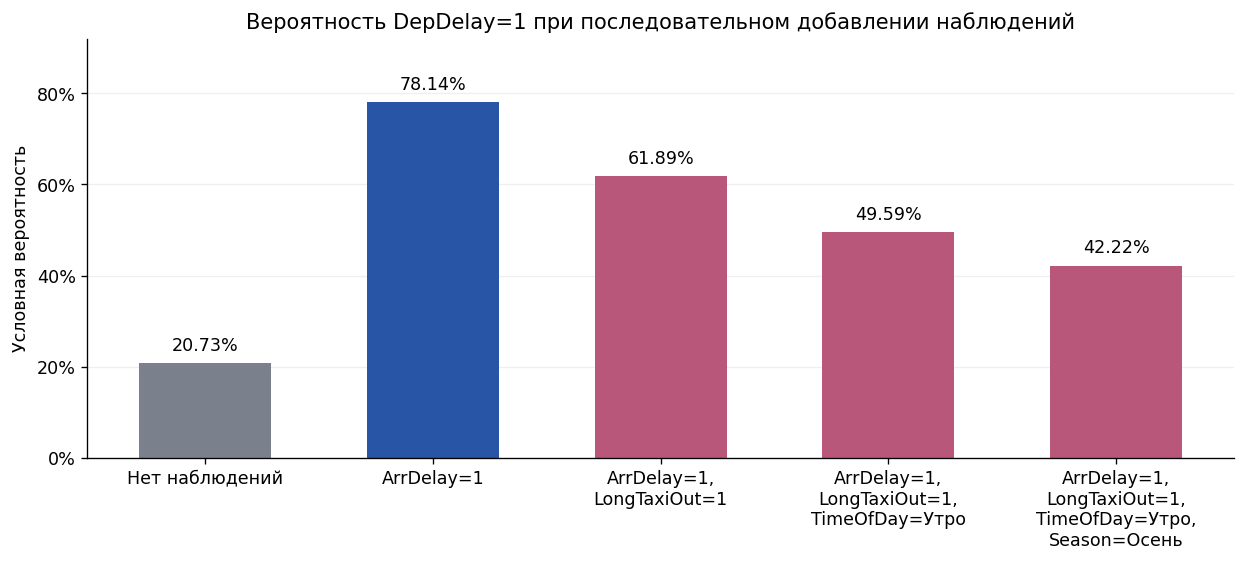

In [9]:
EVIDENCE_STEPS = [
    ("Нет наблюдений", {}),
    ("ArrDelay=1", {"ArrDelay": 1}),
    ("ArrDelay=1,\nLongTaxiOut=1", {"ArrDelay": 1, "LongTaxiOut": 1}),
    ("ArrDelay=1,\nLongTaxiOut=1,\nTimeOfDay=Утро", {"ArrDelay": 1, "LongTaxiOut": 1, "TimeOfDay": "Утро"}),
    ("ArrDelay=1,\nLongTaxiOut=1,\nTimeOfDay=Утро,\nSeason=Осень", {"ArrDelay": 1, "LongTaxiOut": 1, "TimeOfDay": "Утро", "Season": "Осень"}),
]

evidence_results = pd.DataFrame([
    {
        "Наблюдения": label.replace("\n", " "),
        "P(DepDelay=1 | evidence)": probability(inference, "DepDelay", evidence, state=1),
    }
    for label, evidence in EVIDENCE_STEPS
])
display(evidence_results.round(4))

dsep_checks = pd.DataFrame([
    {"Пара узлов": "DepDelay и LongTaxiOut", "Наблюдения": "BusyOrigin",
     "Есть активный путь": model.is_dconnected("DepDelay", "LongTaxiOut", observed=["BusyOrigin"])},
    {"Пара узлов": "DepDelay и LongTaxiOut", "Наблюдения": "BusyOrigin, ArrDelay",
     "Есть активный путь": model.is_dconnected("DepDelay", "LongTaxiOut", observed=["BusyOrigin", "ArrDelay"])},
    {"Пара узлов": "Season и ArrDelay", "Наблюдения": "DepDelay",
     "Есть активный путь": model.is_dconnected("Season", "ArrDelay", observed=["DepDelay"])},
    {"Пара узлов": "TimeOfDay и LongTaxiOut", "Наблюдения": "Нет",
     "Есть активный путь": model.is_dconnected("TimeOfDay", "LongTaxiOut")},
])
print("Проверка активных путей (d-разделение):")
display(dsep_checks)

fig, ax = plt.subplots(figsize=(10.5, 4.8))
values = evidence_results["P(DepDelay=1 | evidence)"].to_numpy()
labels = [label for label, _ in EVIDENCE_STEPS]
bar_colors = [COLORS["muted"], COLORS["main"], COLORS["accent"], COLORS["accent"], COLORS["accent"]]
bars = ax.bar(labels, values, color=bar_colors, width=0.58)
ax.bar_label(bars, labels=[f"{v:.2%}" for v in values], padding=5)
ax.set(
    title="Вероятность DepDelay=1 при последовательном добавлении наблюдений",
    ylabel="Условная вероятность",
    ylim=(0, 0.92),
)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 8. Анализ структуры

Удалим ребро LongTaxiOut -> ArrDelay, сохранив все 7 узлов, и заново оценим параметры сети на тех же данных (BDeu, ESS = 5). Затем повторим запрос P(DepDelay = 1 | ArrDelay = 1, LongTaxiOut = 1) и оценим качество совместного распределения по метрике NLL на контрольной выборке (20% данных).

- Изменился ли результат: да, существенно. В исходной сети P(DepDelay = 1 | ArrDelay = 1, LongTaxiOut = 1) = 61.89%, а после удаления ребра LongTaxiOut -> ArrDelay оценка вырастает до 78.59% (+16.70 п.п.). Для противоположного случая P(DepDelay = 1 | ArrDelay = 1, LongTaxiOut = 0) вероятность падает с 89.24% до 78.31% (-10.93 п.п.). При этом NLL на контрольной выборке ухудшается с 5.4869 до 5.5141, то есть модель без этого ребра хуже описывает совместное распределение данных.
- Почему структура графа влияет на вероятностный вывод: граф задает набор условных независимостей и факторизацию совместного распределения. Удаление LongTaxiOut -> ArrDelay разрушает коллайдер DepDelay -> ArrDelay <- LongTaxiOut. После этого модель больше не считает долгое руление возможной причиной опоздания прилета, и эффект explaining away исчезает. Остается только слабый положительный путь через развилку DepDelay <- BusyOrigin -> LongTaxiOut (долгое руление слегка указывает на крупный хаб, где задержки вылета чуть выше), поэтому оценка при LongTaxiOut = 1 (78.59%) даже оказывается чуть выше, чем при LongTaxiOut = 0 (78.31%).
- Насколько уверенно можно выбирать направление ребер только по наблюдаемым данным: по одним лишь наблюдаемым данным направление ребер часто определить невозможно из-за марковской эквивалентности. Разные DAG с одинаковым скелетом и одинаковым набором коллайдеров (например, цепь A -> B -> C, обратная цепь A <- B <- C и развилка A <- B -> C) кодируют ровно одну и ту же условную независимость A _|_ C | B и дают одинаковое правдоподобие на данных. Наблюдательные данные позволяют уверенно выделять v-структуры (коллайдеры), но для ориентации остальных ребер необходимы предметные знания и временной порядок событий.

,Структура,"P(DepDelay=1 | ArrDelay=1, LongTaxiOut=1)","P(DepDelay=1 | ArrDelay=1, LongTaxiOut=0)",NLL на test
0,Исходная сеть,0.6189,0.8924,5.4869
1,Без ребра LongTaxiOut -> ArrDelay,0.7859,0.7831,5.5141


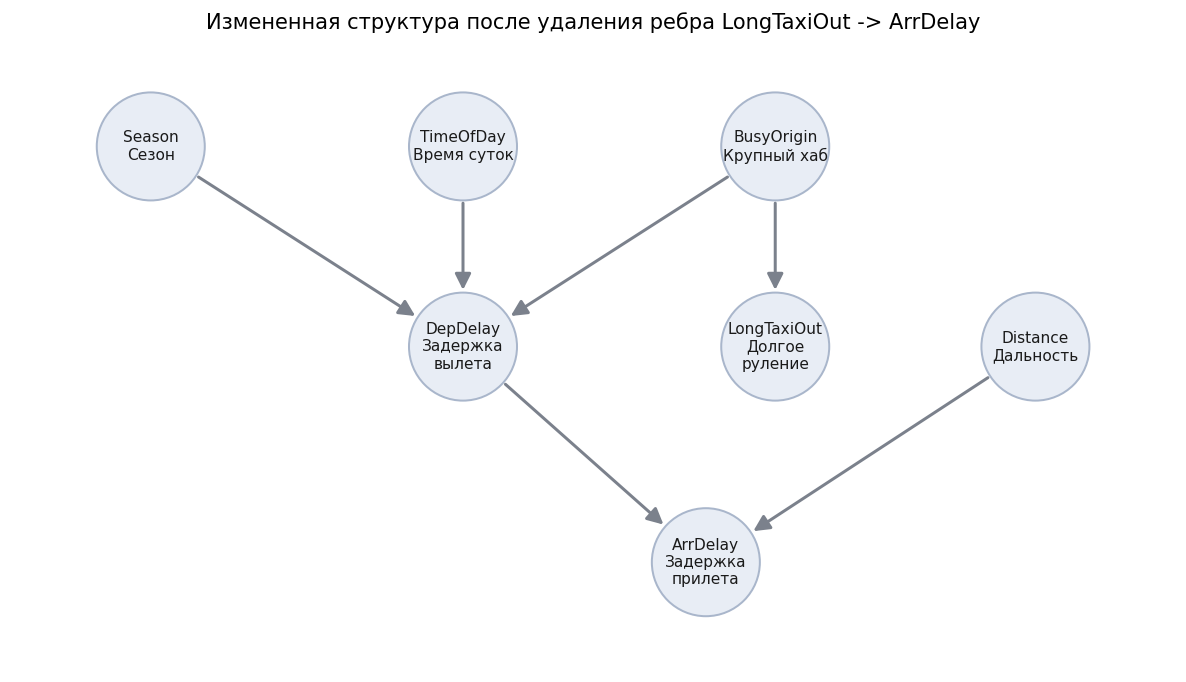

In [10]:
REDUCED_EDGES = tuple(edge for edge in EDGES if edge != ("LongTaxiOut", "ArrDelay"))
reduced_model = fit_network(data, REDUCED_EDGES, method="bdeu")
reduced_inference = VariableElimination(reduced_model)

def joint_nll(fitted_model: DiscreteBayesianNetwork, eval_df: pd.DataFrame) -> float:
    log_probs = np.zeros(len(eval_df), dtype=float)
    for node in fitted_model.nodes():
        cpd = fitted_model.get_cpds(node)
        vars_order = cpd.variables
        state_maps = {v: {s: i for i, s in enumerate(cpd.state_names[v])} for v in vars_order}
        idx = tuple(eval_df[v].map(state_maps[v]).to_numpy() for v in vars_order)
        probs = np.asarray(cpd.values)[idx]
        log_probs += np.log(probs)
    return float(-log_probs.mean())

rng = np.random.default_rng(SEED)
perm = rng.permutation(len(data))
split_idx = int(0.8 * len(data))
train_df = data.iloc[perm[:split_idx]].reset_index(drop=True)
test_df = data.iloc[perm[split_idx:]].reset_index(drop=True)

model_tr = fit_network(train_df, EDGES, method="bdeu")
reduced_tr = fit_network(train_df, REDUCED_EDGES, method="bdeu")

structure_comparison = pd.DataFrame([
    {
        "Структура": "Исходная сеть",
        "P(DepDelay=1 | ArrDelay=1, LongTaxiOut=1)": probability(inference, "DepDelay", {"ArrDelay": 1, "LongTaxiOut": 1}),
        "P(DepDelay=1 | ArrDelay=1, LongTaxiOut=0)": probability(inference, "DepDelay", {"ArrDelay": 1, "LongTaxiOut": 0}),
        "NLL на test": joint_nll(model_tr, test_df),
    },
    {
        "Структура": "Без ребра LongTaxiOut -> ArrDelay",
        "P(DepDelay=1 | ArrDelay=1, LongTaxiOut=1)": probability(reduced_inference, "DepDelay", {"ArrDelay": 1, "LongTaxiOut": 1}),
        "P(DepDelay=1 | ArrDelay=1, LongTaxiOut=0)": probability(reduced_inference, "DepDelay", {"ArrDelay": 1, "LongTaxiOut": 0}),
        "NLL на test": joint_nll(reduced_tr, test_df),
    },
])
display(structure_comparison.round(4))
draw_network(reduced_model, title="Измененная структура после удаления ребра LongTaxiOut -> ArrDelay")

## 9. Причинность

Построенную байесовскую сеть нельзя считать полноценной причинной моделью в строгом смысле. Сама по себе байесовская сеть задает лишь факторизацию совместного распределения и набор условных независимостей, а направленные ребра не доказывают причинно-следственную связь по наблюдаемым данным.

Какие связи можно обоснованно трактовать как причинные на основе предметной области и хронологии событий:
- DepDelay -> ArrDelay и LongTaxiOut -> ArrDelay: фактическое время прилета физически складывается из времени вылета, длительности руления и времени полета, поэтому задержка на более раннем этапе напрямую сдвигает более поздний этап.
- BusyOrigin -> LongTaxiOut: инфраструктура и пропускная способность конкретного аэропорта существуют до выполнения рейса и влияют на очередь на взлет.

Почему всю сеть нельзя использовать как строгую причинную модель для оценки вмешательств do(...):
- Скрытые общие причины (confounders): в модели отсутствуют явные погодные условия в аэропорту вылета и прилета, загруженность воздушного пространства (ATC/NAS), техническое состояние борта и специфика конкретных авиакомпаний. Например, гроза в аэропорту одновременно вызывает и задержку вылета (DepDelay), и длительное руление (LongTaxiOut), и увеличение времени полета (ArrDelay).
- Агрегированность факторов: TimeOfDay и Season сами по себе не вызывают задержки физически, а выступают прокси-переменными для накопленных сбоев в расписании и сезонной погоды.
- Отсутствие экспериментальных интервенций: все параметры оценены по наблюдательным данным, поэтому запросы вида P(A | B) отражают статистическое обновление вероятностей при наблюдении, а не эффект вмешательства do(B).

## 10. Итог

- Что удалось узнать с помощью сети: для внутренних рейсов США 2024 года базовая доля задержек вылета составляет 20.73%, задержек прилета — 21.58%. Вероятность опоздания прилета возрастает до 36.98% летним вечером, а при уже возникшей задержке вылета достигает 82.83% на коротких маршрутах и 74.62% на дальних.
- Наиболее интересные зависимости: во-первых, выраженный коллайдер DepDelay -> ArrDelay <- LongTaxiOut, в котором долгое руление существенно снижает вероятность того, что опоздавший рейс был задержан еще на вылете (с 78.14% до 61.89%). Во-вторых, компенсирующее влияние дальности рейса: на дальних перелетах экипаж чаще успевает отыграть задержку вылета в воздухе.
- Влияние evidence на вероятности: добавление наблюдений не обязано монотонно увеличивать или уменьшать вероятность. В эксперименте для DepDelay = 1 наблюдение ArrDelay = 1 подняло вероятность с 20.73% до 78.14%, после чего добавление LongTaxiOut = 1, TimeOfDay = Утро и Season = Осень последовательно снизило ее до 61.89%, 49.59% и 42.22%.
- Зависимость результатов от структуры: удаление одного ребра LongTaxiOut -> ArrDelay изменило ответ на запрос P(DepDelay = 1 | ArrDelay = 1, LongTaxiOut = 1) на +16.70 п.п. (с 61.89% до 78.59%) и ухудшило NLL на контрольной выборке с 5.4869 до 5.5141, полностью устранив эффект explaining away.
- Ограничения модели: потеря части информации при бинаризации непрерывных задержек и руления (пороги 15 и 20 минут не различают задержку в 20 минут и 3 часа); исключение отмененных и перенаправленных рейсов (1.64% выборки); отсутствие скрытых общих факторов (погода, авиакомпания, аэропорт прилета); невозможность делать строгие причинные выводы без дополнительных допущений.